<a href="https://colab.research.google.com/github/BarGinger/Deep_Learning_MEG/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning - Assigment 2

### Group Number: 22

### Teammates:
1. **Mahshid Jafar Tajrishi**
2. **Bar Melinarskiy**
3. **Cis van Aken**
4. **Simon van Klompenburg**

## Imports entire notebook

In [1]:
# Helper function to check if the code is running in Google Colab
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

# Usage
if is_colab():
    print("Running in Google Colab")
else:
    print("Not running in Google Colab")


# Importing libraries
import pandas as pd
import numpy as np
from Model import MEGClassifier
import Utils as utils
import torch
import matplotlib.pyplot as plt
import os
import random


Not running in Google Colab


## Global Definitions

In [2]:
# Path to the zip file
data_dir = "./Data"
google_drive_folder = "/content/drive/MyDrive/UU"
zip_path = f"{data_dir}/Final Project data.zip"
output_dir = "./Output"
model_dir = "./Models"

# check if outpiut directory exists
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# check if model directory exists
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Set the device to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

debug_mode = False

# Set pandas display options to show all columns
pd.set_option('display.max_columns', None)

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# model and data related parameters
scaler_type = utils.NormalizationType.Z_SCORE_LOCAL  # or MINMAX_LOCAL, Z_SCORE_TIMEWISE
which_dataset = "intra"  # or "cross"
downsample = True  # or False
downsample_rate = 0  
if downsample:
    downsample_rate = 9

model_name = "EEGNet"
model_pth_path = f"{model_dir}/best_model_{model_name}.pth"

### Check if we are in google colab then we need to mount the drive

In [3]:
# If we are in colab and we need to mount the drive
if is_colab():
  from google.colab import drive
  # Mount Google Drive
  drive.mount('/content/drive')
  print("Google Drive mounted successfully.")
  data_dir = f"{google_drive_folder}/Final Project data"
else:
  print("Not in Google Colab.")

Not in Google Colab.


### Check if we have cude

In [4]:
# Check if CUDA is available
print(torch.__version__)
print(torch.version.cuda)  # Should match CUDA 12.5
print(torch.backends.cudnn.version())  # Should return a version, not None
print(torch.cuda.is_available())  # Should return True

2.5.1
None
90100
True


### Extract the Zip File

In [5]:
import zipfile

# Check if the dataset is already extracted, if not extract it
if not os.path.exists(data_dir):
    print("Extracting the dataset...")
    #unzip
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
    #list files in the extracted dir
    os.listdir(data_dir)
else:
    print("Dataset already extracted.")

Dataset already extracted.


### Load one example

Matrix shape: (248, 35624)


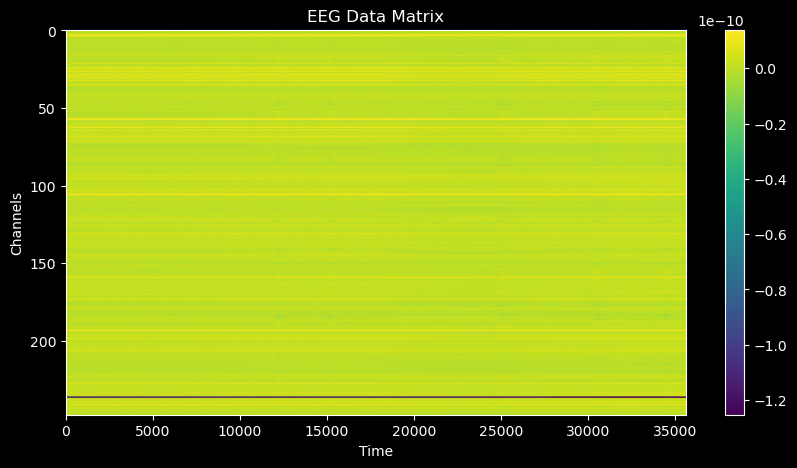

In [6]:
## peak into a matrix to see the data
matrix = utils.get_dataset_from_h5py(f"{data_dir}/Intra/train/task_working_memory_105923_3.h5")
if matrix is not None:
    print(f"Matrix shape: {matrix.shape}")


# plot that matrix
plt.figure(figsize=(10, 5))
plt.imshow(matrix, aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("EEG Data Matrix")
plt.xlabel("Time")
plt.ylabel("Channels")
plt.show()

### Load the datasets

In [7]:
## load the chosen dataset/s
print(f"Loading {which_dataset} dataset...")
if which_dataset == "intra":
    # INTRA TRAIN
    intra_train_data_scaled, intra_train_df = utils.try_load_scaled("intra_train", scaler_type)
    if intra_train_data_scaled is None:
        intra_train_folder = os.path.join(data_dir, "Intra", "train")
        intra_train_data, intra_train_df = utils.load_eeg_data_and_metadata(intra_train_folder, split="train")
        intra_train_data_scaled, intra_train_df = utils.scale_and_cache(
            intra_train_data, intra_train_df, "intra_train", scaler_type, downsample_factor=downsample_rate)

    # INTRA TEST
    intra_test_data_scaled, intra_test_df = utils.try_load_scaled("intra_test", scaler_type)
    if intra_test_data_scaled is None:
        intra_test_folder = os.path.join(data_dir, "Intra", "test")
        intra_test_data, intra_test_df = utils.load_eeg_data_and_metadata(intra_test_folder, split="test")
        intra_test_data_scaled, intra_test_df = utils.scale_and_cache(
            intra_test_data, intra_test_df, "intra_test", scaler_type, downsample_factor=downsample_rate)
        
if which_dataset == "cross":
    # CROSS TRAIN
    cross_train_data_scaled, cross_train_df = utils.try_load_scaled("cross_train", scaler_type)
    if cross_train_data_scaled is None:
        cross_train_folder = os.path.join(data_dir, "Cross", "train")
        cross_train_data, cross_train_df = utils.load_eeg_data_and_metadata(cross_train_folder, split="train")
        cross_train_data_scaled, cross_train_df = utils.scale_and_cache(
            cross_train_data, cross_train_df, "cross_train", scaler_type, downsample_factor=downsample_rate)

    # CROSS TEST (list of datasets)
    cross_test_data_scaled = []
    cross_test_df_list = []
    for i in range(1, 4):
        prefix = f"cross_test{i}"
        scaled, meta = utils.try_load_scaled(prefix, scaler_type)
        if scaled is None:
            folder = os.path.join(data_dir, "Cross", f"test{i}")
            data, df = utils.load_eeg_data_and_metadata(folder, split=f"test{i}")
            scaled, meta = utils.scale_and_cache(data, df, prefix, scaler_type, downsample_factor=downsample_rate)
        cross_test_data_scaled.append(scaled)
        cross_test_df_list.append(meta)

print(f"Data for dataset {which_dataset} was loaded successfully")

Loading intra dataset...
Loading cached: Data\Normalized\z_score_local\intra_train_scaled.pt
Loading cached: Data\Normalized\z_score_local\intra_test_scaled.pt
Data for dataset intra was loaded successfully


c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\Utils.py:199: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any iss

### Definitions for training and logging

In [8]:
# Choose which dataset to train on:
if which_dataset == "intra":
    train_data, train_df = intra_train_data_scaled, intra_train_df
else: # cross
    train_data, train_df = cross_train_data_scaled, cross_train_df

model_name = f"MEGClassifier_{which_dataset}"
model_pth_path = f"{model_dir}/best_model_{model_name}.pth"
model_json_path = f"{model_dir}/best_model_{model_name}.json"
best_model = None

### Train

In [9]:
import optuna
import json

number_of_trials = 1

# Prepare a global DataFrame for metrics
all_metrics_df = utils.create_metrics_df()

# Define a wrapper so Optuna only gets the accuracy
def optuna_objective(trial):
    global all_metrics_df
    best_val_acc, updated_metrics_df = utils.objective(
        trial, all_metrics_df, train_data, train_df, device
    )
    all_metrics_df = updated_metrics_df  # update global after each trial
    return best_val_acc  # maximize accuracy

# Run Optuna and save best model after all trials
study = optuna.create_study(direction="maximize")
study.optimize(optuna_objective, n_trials=number_of_trials)

# Save best model after all trials
best_trial = study.best_trial
best_params = best_trial.params
best_params["input_channels"] = train_data.shape[1]
best_params["num_classes"] = len(np.unique(train_df['task_type']))

# Create the model with the best hyperparameters
best_model = MEGClassifier(**{k: v for k, v in best_params.items() if k in MEGClassifier.__init__.__code__.co_varnames}).to(device)
torch.save(best_model.state_dict(), f"{model_dir}/best_model.pth")
print(f"Best model saved to {model_pth_path}")

with open(f"{model_dir}/best_hyperparameters.json", "w") as f:
    json.dump(best_params, f)
print(f"Best hyperparameters saved to {model_json_path}")

# Save metrics
csv_path = f"{output_dir}/all_trials_metrics.csv"
all_metrics_df.to_csv(csv_path, index=False)
print(f"All metrics saved to {csv_path}")
print("Best hyperparameters:", best_params)
print("Best validation accuracy:", study.best_value)

[I 2025-05-19 17:44:12,556] A new study created in memory with name: no-name-1760ecf1-f0dc-4554-a812-ab0666e57a86
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains [128, 256] which is of type list.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains [64, 128] which is of type list.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains [256, 512] which is of type list.
  warnings.warn(message)
c:\Users\bar24\an

Trial: 1:   0%|          | 0/100 [00:00<?, ?epoch/s]

c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\Utils.py:381: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_metrics_df = pd.concat([all_metrics_df, pd.DataFrame([row])], ignore_index=True)
[I 2025-05-19 17:48:33,382] Trial 0 finished with value: 1.0 and parameters: {'num_temporal_filters': 8, 'temporal_kernel_size': 32, 'dropout_rate': 0.4, 'activation': 'elu', 'pool_size': 4, 'conv2d_channels': [64, 128], 'transformer_d_model': 512, 'transformer_nhead': 16, 'transformer_dim_feedforward': 1024, 'transformer_layers': 6, 'fc_hidden': 128, 'fc_dropout': 0.1, 'learning_rate': 0.00038549247293287464, 'batch_size': 64, 'input_time_leng

Early stopping triggered after 51 epochs.
Best model saved to ./Models/best_model_MEGClassifier_intra.pth
Best hyperparameters saved to ./Models/best_model_MEGClassifier_intra.json
All metrics saved to ./Output/all_trials_metrics.csv
Best hyperparameters: {'num_temporal_filters': 8, 'temporal_kernel_size': 32, 'dropout_rate': 0.4, 'activation': 'elu', 'pool_size': 4, 'conv2d_channels': [64, 128], 'transformer_d_model': 512, 'transformer_nhead': 16, 'transformer_dim_feedforward': 1024, 'transformer_layers': 6, 'fc_hidden': 128, 'fc_dropout': 0.1, 'learning_rate': 0.00038549247293287464, 'batch_size': 64, 'input_time_length': 512, 'stride': 128, 'input_channels': 248, 'num_classes': 4}
Best validation accuracy: 1.0


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\torch\nn\modules\transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


In [18]:
import importlib
import Utils
importlib.reload(Utils)

<module 'Utils' from 'c:\\Users\\bar24\\OneDrive - Universiteit Utrecht\\Documents\\School\\UU Data Sceince MSc\\1st Year\\Period 4\\Deep learning (INFOMDLR)\\Assignments\\Deep_Learning_MEG\\Utils.py'>

In [21]:
overall_metrics, per_task = utils.evaluate_model_on_testset(
    best_model, intra_test_data_scaled, intra_test_df, device
)
# print("Overall:", overall_metrics["overall_accuracy"], overall_metrics["overall_F1"], overall_metrics["overall_recall"], overall_metrics["overall_precision"])
print("Per-task:", per_task)
print("Overall:", overall_metrics)

c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\Utils.py:475: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = []


Per-task: {'rest': {'accuracy': 0.0, 'F1': 0.0, 'recall': 0.0, 'precision': 0.0}, 'task_motor': {'accuracy': 0.0, 'F1': 0.0, 'recall': 0.0, 'precision': 0.0}, 'task_story_math': {'accuracy': 1.0, 'F1': 1.0, 'recall': 1.0, 'precision': 1.0}, 'task_working_memory': {'accuracy': 0.0, 'F1': 0.0, 'recall': 0.0, 'precision': 0.0}}
Overall: (0.25, 0.1, 0.25, 0.0625)
